::: {.sb-downloads}
[Download this notebook](../downloads/solutions-noise-cancellation.ipynb){download="solutions-noise-cancellation.ipynb"}  
Data: [noisy_digits.csv](../downloads/data/noisy_digits.csv){download="noisy_digits.csv"} · [noisy_digits_labels.csv](../downloads/data/noisy_digits_labels.csv){download="noisy_digits_labels.csv"}

Put the data files in a folder named `data` next to the notebook.
:::

::: {.sb-lesson-links}
[← Back to the exercises](../exercises/noise-cancellation.ipynb)
:::

::: {.callout-tip}
Try the exercises on your own first: you learn much more by searching than by reading a solution.
:::

PCA can also **clean** data. In this exercise, we classify handwritten digits that are hidden under a lot of noise, and use PCA to remove part of it.

## The dataset {#ex-the-dataset}
`../data/noisy_digits.csv` contains 1,797 images of handwritten digits, 8 × 8 pixels each: one row per image, one column per pixel (`pixel_0` to `pixel_63`). They are scikit-learn's digits (pixel values from 0 to 16) to which we added random Gaussian noise with a standard deviation of 4; negative values were then set to 0. `../data/noisy_digits_labels.csv` gives the digit of each image (column `digit`).

Because we know how the noise was made, we can also load the **clean** images (`load_digits()`, bundled with scikit-learn) and check how well PCA removes the noise. In real life, you never have the clean version.

1. Import the libraries and load the data (given).

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# colour palette of the course
pio.templates["course"] = go.layout.Template(
    layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"]
)
pio.templates.default = "plotly_white+course"

digits = pd.read_csv("../data/noisy_digits.csv")
labels = pd.read_csv("../data/noisy_digits_labels.csv")["digit"]
clean = load_digits().data                      # the same images, without noise (same order)
digits.head()

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_54,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63
0,4.1,6.6,9.6,9.1,3.4,1.3,3.4,2.0,7.2,3.0,...,5.1,2.8,0.0,0.0,8.4,12.2,7.6,0.0,0.0,0.0
1,0.0,4.6,0.0,15.5,14.7,5.6,0.0,0.0,7.9,0.4,...,0.7,0.7,1.6,0.1,0.0,7.7,17.4,6.4,0.0,0.5
2,0.0,3.6,2.0,2.3,15.5,0.6,0.0,0.0,0.0,0.0,...,2.0,2.4,0.0,0.7,2.8,5.3,6.8,23.7,1.1,0.0
3,0.0,4.8,1.8,10.9,8.4,0.0,0.0,0.7,0.0,1.2,...,9.6,0.5,0.0,0.0,4.6,16.3,13.0,7.1,0.0,7.0
4,5.9,4.4,0.7,0.0,11.8,0.0,2.5,4.1,0.0,5.3,...,0.8,0.0,1.5,0.0,0.0,2.3,14.1,0.0,0.0,0.0


## Looking at the images {#ex-looking-at-the-images}

2. How many images and pixels are there? What are the smallest and largest pixel values? Display the first 20 noisy images, with their digit as a title.

::: {.callout-tip collapse="true" title="Show hint"}
Hint: `digits.values[i].reshape(8, 8)` turns row `i` into an 8 × 8 image; `plt.subplots(2, 10)` and `ax.imshow(image, cmap="gray_r")` draw them.
:::

(1797, 64)
Pixel values from 0.0 to 30.3


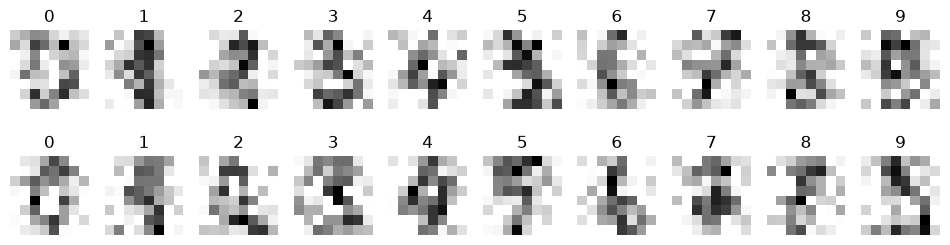

In [ ]:
print(digits.shape)
print("Pixel values from", digits.values.min(), "to", digits.values.max())

fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for i, ax in enumerate(axes.flat):
    ax.imshow(digits.values[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(labels[i])
    ax.axis("off")
plt.show()

**1,797 images of 64 pixels. The noisy pixels go from 0 to 30.3 (the clean ones from 0 to 16). Some digits are still readable, others (the 1s, the 8s...) are hard to recognise even for a human.**

3. Split the data into a train set and a test set (25% for the test set, `random_state=0`, `stratify=labels`). Keep the clean version of the test images too: `clean[X_test.index]`.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(digits, labels, test_size=0.25, random_state=0, stratify=labels)
clean_test = clean[X_test.index]
print(X_train.shape, X_test.shape)

(1347, 64) (450, 64)


4. Should we standardise the pixels before the PCA? Think about what the pixels measure, and about the pixels on the border of the images.

**No. All the pixels are in the same unit (a grey level), so their variances are comparable, and that is what we want PCA to use. The pixels on the border are almost always 0 in the clean images: their variance comes only from the noise. Standardising would give them a variance of 1, the same weight as the pixels that draw the digits, and the components would pay more attention to noise. We check this in question 11.**

## A classifier on the noisy pixels {#ex-a-classifier-on-the-noisy-pixels}

5. Train a `SVC()` (support vector classifier, default settings) on the noisy training pixels and display its accuracy on the test set. This is our baseline.

In [ ]:
svc = SVC()
svc.fit(X_train, y_train)
print(f"Accuracy on the noisy pixels (64 features): {svc.score(X_test, y_test):.3f}")

Accuracy on the noisy pixels (64 features): 0.931


**The test accuracy is 0.931 on the 64 noisy pixels.**

## Denoising with PCA {#ex-denoising-with-pca}

6. Fit a PCA on the training images that keeps **70% of the variance**. How many components does it keep?

In [ ]:
pca = PCA(n_components=0.7)
pca.fit(X_train)
print(f"{pca.n_components_} components keep {pca.explained_variance_ratio_.sum():.1%} of the variance")

20 components keep 70.3% of the variance


**20 components out of 64 keep 70.3% of the variance.**

7. Denoise the test images: project them on the components (`transform`) and go back to the pixels (`inverse_transform`). Display 10 test images in three rows: noisy, denoised, clean. Then compute the root mean squared difference between the clean images and (a) the noisy images, (b) the denoised images.

::: {.callout-tip collapse="true" title="Show hint"}
Hint: the root mean squared difference between two arrays `a` and `b` is `np.sqrt(((a - b) ** 2).mean())`.
:::

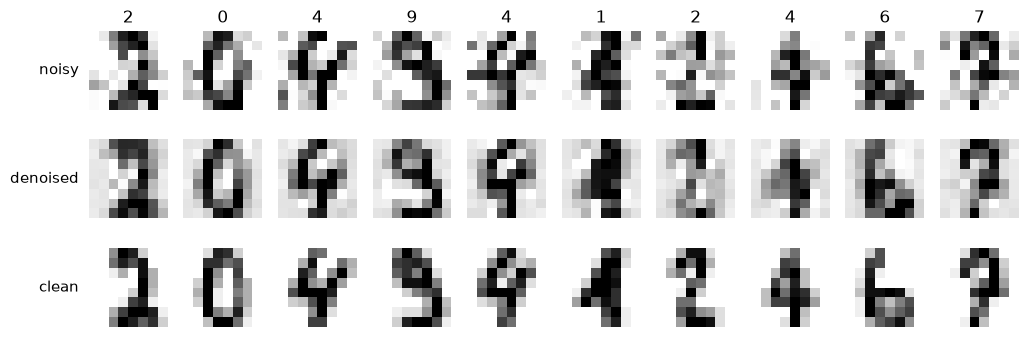

Root mean squared difference with the clean images: noisy 3.32, denoised 2.74


In [ ]:
denoised = pca.inverse_transform(pca.transform(X_test))

fig, axes = plt.subplots(3, 10, figsize=(12, 4))
for j in range(10):
    for row, (images, name) in enumerate([(X_test.values, "noisy"), (denoised, "denoised"), (clean_test, "clean")]):
        axes[row, j].imshow(images[j].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
        axes[row, j].axis("off")
    axes[0, j].set_title(y_test.values[j])
for row, name in enumerate(["noisy", "denoised", "clean"]):
    axes[row, 0].text(-1.5, 3.5, name, ha="right", va="center", fontsize=11)
plt.show()

rmse_noisy = np.sqrt(((X_test.values - clean_test) ** 2).mean())
rmse_denoised = np.sqrt(((denoised - clean_test) ** 2).mean())
print(f"Root mean squared difference with the clean images: noisy {rmse_noisy:.2f}, denoised {rmse_denoised:.2f}")

**The denoised images are smoother: the random dots in the background mostly disappear and the strokes of the digits come back. They are still blurry, because 20 components cannot rebuild every detail of a digit. The difference with the clean images drops from 3.32 (noisy) to 2.74 (denoised): PCA removed part of the noise, not all of it.**

8. Train a new `SVC()` on the PCA features of the training set (the 20 coordinates, `pca.transform(X_train)`), and compute its accuracy on the PCA features of the test set. Compare with question 5.

In [ ]:
X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)

svc_pca = SVC()
svc_pca.fit(X_train_pca, y_train)
print(f"Accuracy on {pca.n_components_} PCA features: {svc_pca.score(X_test_pca, y_test):.3f}")

Accuracy on 20 PCA features: 0.949


**The accuracy goes from 0.931 (64 noisy pixels) to 0.949 (20 components): better, with 3 times fewer features, so a faster model. Removing the noise helps the classifier more than the lost details hurt it.**

## Why does it work? {#ex-why-does-it-work}

9. Make an image of pure noise with the same shape as the training set: `np.random.default_rng(0).normal(0, 4, X_train.shape)`. Fit a PCA with all the components on it, and another one on the noisy training images. Plot the `explained_variance_` of both (one curve each, log scale for the y axis). What do you notice? Explain why PCA removes noise.

In [ ]:
pure_noise = np.random.default_rng(0).normal(0, 4, X_train.shape)
var_noise = PCA().fit(pure_noise).explained_variance_
var_digits = PCA().fit(X_train).explained_variance_
print("Pure noise, first and last eigenvalues:", var_noise[[0, -1]].round(1))
print("Noisy digits, components 1, 20, 40, 64:", var_digits[[0, 19, 39, 63]].round(1))

k = np.arange(1, 65)
fig = go.Figure()
fig.add_trace(go.Scatter(x=k, y=var_digits, mode="lines+markers", name="noisy digits"))
fig.add_trace(go.Scatter(x=k, y=var_noise, mode="lines+markers", name="pure noise (σ = 4)"))
fig.add_vline(x=pca.n_components_, line_dash="dot", annotation_text="70% of the variance")
fig.update_layout(title="Variance of each component", xaxis_title="component", yaxis_title="explained variance",
                  yaxis_type="log")
fig.show()

Pure noise, first and last eigenvalues: [23.6  9.9]
Noisy digits, components 1, 20, 40, 64: [153.4  22.   10.7   4.3]


**For pure noise, no component stands out: the variances go slowly from 23.6 to 9.9, around $4^2 = 16$ (they are not exactly equal only because we have a finite sample). Noise has no favourite direction: it spreads evenly over all 64 components. For the noisy digits, the first components have a much larger variance (153.4 for PC1), because the shapes of the digits are strongly correlated between neighbouring pixels: the signal is concentrated in a few directions. Around component 20 (variance 22.0) the curve reaches the band of pure noise, and from about component 30 it goes below it (10.7 for component 40, 4.3 for the last one; the noise on the border pixels is smaller because the negative values were set to 0). These components carry no more than noise.**

**So the first components hold the digit plus a small share of the noise, and the last ones hold almost only noise. Keeping the first components and dropping the others removes most of the noise and keeps most of the digit.**

## Choosing the share of variance {#ex-choosing-the-share-of-variance}

10. With 5-fold cross-validation on the **training set** (`StratifiedKFold(5, shuffle=True, random_state=0)`), compare a `SVC()` alone and pipelines `PCA(n_components=share)` → `SVC()` for `share` in 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9 and 0.95. Which share is best? What happens when it is too small or too large?

In [ ]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)
print(f"no PCA         : {cross_val_score(SVC(), X_train, y_train, cv=cv).mean():.3f}")
for share in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    pipe = make_pipeline(PCA(n_components=share), SVC())
    score = cross_val_score(pipe, X_train, y_train, cv=cv).mean()
    print(f"PCA {share:<4} → SVC : {score:.3f}")

no PCA         : 0.928
PCA 0.3  → SVC : 0.771


PCA 0.4  → SVC : 0.837


PCA 0.5  → SVC : 0.909


PCA 0.6  → SVC : 0.929


PCA 0.7  → SVC : 0.939


PCA 0.8  → SVC : 0.934


PCA 0.9  → SVC : 0.933


PCA 0.95 → SVC : 0.937


**Without PCA the cross-validated accuracy is 0.928. With too little variance (30%: 0.771, 40%: 0.837) the components cannot describe the digits anymore. The best share is 70% (0.939). Beyond it, the accuracy goes down a little (0.933 to 0.937), because we keep more and more noise. The share used in question 6 was not a lucky guess on the test set: cross-validation on the training set chooses it too.**

11. Check your answer to question 4: build a pipeline `StandardScaler()` → `PCA(n_components=0.7)` → `SVC()`, fit it on the training set and compute its test accuracy. How many components does the PCA keep now?

In [ ]:
pipe_scaled = make_pipeline(StandardScaler(), PCA(n_components=0.7), SVC())
pipe_scaled.fit(X_train, y_train)
print(f"With standardisation: {pipe_scaled[1].n_components_} components, test accuracy {pipe_scaled.score(X_test, y_test):.3f}")

With standardisation: 30 components, test accuracy 0.896


**With standardisation, PCA needs 30 components for 70% of the variance (instead of 20), and the test accuracy falls to 0.896 (0.949 without standardisation). The noise-only pixels now have as much variance as the useful ones, so the variance is less concentrated, and the components keep more noise. Standardise when the units differ; not when they are the same and the spread is meaningful.**